# 01 · Preliminary EDA: what is in the two Bondora sources?

**Purpose.** Before designing the warehouse, load both raw sources as they were downloaded and answer five questions:

1. Are the raw files the exact snapshots recorded in their manifests?
2. What does each source contain (rows, columns, types, date coverage, countries)?
3. Do the two sources share any columns?
4. Can loans be matched across sources, and on which key?
5. Is there a usable default target, and what does the default rate look like?

**Sources** (downloaded with `python -m pdengine.download_data`, see `README.md`):

| Source | File | Role in this project |
|---|---|---|
| Kaggle snapshot (`sid321axn/bondora-peer-to-peer-lending-loan-data`) | `data/raw/kaggle/LoanData_Bondora.csv` | Borrower features at application |
| Official Bondora / Go & Grow public feed | `data/raw/official/loan_dataset_investor.xlsx` | Loan outcomes, refreshed monthly |

This notebook only reads data. It writes one file: a Parquet copy of the official Excel workbook in `data/processed/` (section 2), because the workbook takes minutes to parse.

## 0. Setup

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)

# Locate the repo root (the folder holding pyproject.toml), whether the notebook
# runs from notebooks/ or from the repo root.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"

KAGGLE_CSV = RAW / "kaggle" / "LoanData_Bondora.csv"
OFFICIAL_XLSX = RAW / "official" / "loan_dataset_investor.xlsx"
OFFICIAL_PARQUET = PROCESSED / "official_loans.parquet"  # same file pdengine.warehouse uses

# Chart style: one series per chart, recessive grid.
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (9, 3.6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984",
    "axes.titleweight": "bold",
})
print("Repo root:", ROOT)

Repo root: c:\Users\P52\Desktop\Credit Risk Scorecard and PD Engine\credit-risk-pd-engine-ifrs9


## 1. Verify the raw files against their manifests

Each download wrote `manifest.json` with the SHA-256 of every file. Re-hashing the files here proves the analysis runs on exactly the recorded snapshot. The official feed is refreshed monthly, so this hash is what ties every later result to a specific data version.

In [2]:
def sha256sum(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


rows = []
for manifest_path in sorted(RAW.glob("*/manifest.json")):
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    for f in manifest["files"]:
        path = ROOT / f["path"]
        actual = sha256sum(path) if path.exists() else None
        rows.append({
            "source": manifest["source"],
            "file": path.name,
            "retrieved_utc": manifest["retrieved_utc"],
            "size_mb": round(f["bytes"] / 1e6, 1),
            "sha256": f["sha256"][:12] + "…",
            "hash_ok": actual == f["sha256"],
        })
manifests = pd.DataFrame(rows)
manifests

,source,file,retrieved_utc,size_mb,sha256,hash_ok
0,kaggle,bondora-peer-to-peer-lending-loan-data.zip,2026-11-02T15:48:19+00:00,36.9,e43140cfad03…,True
1,kaggle,LoanData_Bondora.csv,2026-11-02T15:48:19+00:00,149.6,465abbefd71d…,True
2,official,loan_dataset_investor.xlsx,2026-11-02T14:15:51+00:00,175.1,633e3fa4f316…,True


In [3]:
assert manifests["hash_ok"].all(), "A raw file does not match its manifest: re-download it."

## 2. Load both sources

The official workbook (~175 MB) is converted once to Parquet; later runs read the Parquet copy in seconds. Loan IDs are read as text so nothing is coerced.

In [4]:
%%time
if not OFFICIAL_PARQUET.exists():
    PROCESSED.mkdir(parents=True, exist_ok=True)
    pd.read_excel(OFFICIAL_XLSX, dtype={"loan_id": "string"}).to_parquet(OFFICIAL_PARQUET, index=False)

official = pd.read_parquet(OFFICIAL_PARQUET)
kaggle = pd.read_csv(KAGGLE_CSV, low_memory=False, dtype={"LoanId": "string"})
print(f"Kaggle snapshot: {kaggle.shape[0]:>9,} rows x {kaggle.shape[1]} columns")
print(f"Official feed:   {official.shape[0]:>9,} rows x {official.shape[1]} columns")

Kaggle snapshot:   179,235 rows x 112 columns
Official feed:     843,755 rows x 31 columns
CPU times: total: 3min 5s
Wall time: 3min 5s


### 2.1 Official feed: columns and types

In [5]:
pd.DataFrame({"dtype": official.dtypes.astype(str), "non_null": official.notna().sum(),
              "pct_missing": (official.isna().mean() * 100).round(1)})

,dtype,non_null,pct_missing
loan_id,string,843755,0.0
country,object,843755,0.0
loan_issued_at,datetime64[ns],843755,0.0
early_repaid_at,datetime64[us],252308,70.1
is_early_repaid_within_14_days,float64,252308,70.1
issued_amount,float64,843755,0.0
loan_status,object,843755,0.0
loan_last_recorded_action_date_local,datetime64[us],390297,53.7
initial_interest_rate,float64,843755,0.0
nr_of_payments,int64,843755,0.0


In [6]:
official.head(3)

,loan_id,country,loan_issued_at,early_repaid_at,is_early_repaid_within_14_days,issued_amount,loan_status,loan_last_recorded_action_date_local,initial_interest_rate,nr_of_payments,principal_balance,principal_debt,principal_paid_total,interest_paid_total,extra_interest_paid_total,late_fee_paid_total,maintenance_fee_paid_total,is_default,next_payment_nr,next_payment_date_local,debt_occured_date_local,days_past_due_principal,months_in_default,months_on_book,loan_status_risk,repaid_amount_total,initial_loan_duration,combined_income,has_default_within_12_months,projected_npv_return,customer_risk_rating
0,0001981E-E281-499C-906E-AB6100D6BF73,Estonia,2020-02-14 13:10:19,2021-03-01 08:41:52,0.0,637.0,Repaid,2021-03-01,0.2866,14,0.0,0.0,637.00,168.04,0.02,0.00,26.64,0.0,0.0,NaT,NaT,NaN,NaN,12.0,Paid Up,831.70,36,NaN,0.0,NaN,None
1,0009E1E6-1880-44DE-9F3F-AFE9011E58C7,Finland,2023-04-19 18:17:39,NaT,NaN,4146.0,Repaid,2025-10-29,0.1927,20,0.0,0.0,2438.49,572.01,0.00,0.00,0.00,0.0,0.0,NaT,2024-07-26,460.0,NaN,15.0,Written Off,3010.50,60,2124.89,0.0,0.11025,None
2,000E567F-C487-4E02-805D-A2D101020413,Estonia,2014-02-15 09:40:02,NaT,NaN,7800.0,Repaid,2019-04-03,0.3000,48,0.0,0.0,7800.00,6704.27,5.73,16.19,781.57,0.0,0.0,NaT,NaT,NaN,NaN,62.0,Paid Up,15291.57,36,NaN,0.0,NaN,None


### 2.2 Kaggle snapshot: columns and types

In [7]:
pd.DataFrame({"dtype": kaggle.dtypes.astype(str), "non_null": kaggle.notna().sum(),
              "pct_missing": (kaggle.isna().mean() * 100).round(1)})

,dtype,non_null,pct_missing
ReportAsOfEOD,object,179235,0.0
LoanId,string,179235,0.0
LoanNumber,int64,179235,0.0
ListedOnUTC,object,179235,0.0
BiddingStartedOn,object,179235,0.0
...,...,...,...
NrOfScheduledPayments,float64,112291,37.3
ReScheduledOn,object,63044,64.8
PrincipalDebtServicingCost,float64,76150,57.5
InterestAndPenaltyDebtServicingCost,float64,76150,57.5


In [8]:
kaggle.head(3)

,ReportAsOfEOD,LoanId,LoanNumber,ListedOnUTC,BiddingStartedOn,BidsPortfolioManager,BidsApi,BidsManual,UserName,NewCreditCustomer,LoanApplicationStartedDate,LoanDate,ContractEndDate,FirstPaymentDate,MaturityDate_Original,MaturityDate_Last,ApplicationSignedHour,ApplicationSignedWeekday,VerificationType,LanguageCode,Age,DateOfBirth,Gender,Country,AppliedAmount,Amount,Interest,LoanDuration,MonthlyPayment,County,City,UseOfLoan,Education,MaritalStatus,NrOfDependants,EmploymentStatus,EmploymentDurationCurrentEmployer,EmploymentPosition,WorkExperience,OccupationArea,HomeOwnershipType,IncomeFromPrincipalEmployer,IncomeFromPension,IncomeFromFamilyAllowance,IncomeFromSocialWelfare,IncomeFromLeavePay,IncomeFromChildSupport,IncomeOther,IncomeTotal,ExistingLiabilities,LiabilitiesTotal,RefinanceLiabilities,DebtToIncome,FreeCash,MonthlyPaymentDay,ActiveScheduleFirstPaymentReached,PlannedPrincipalTillDate,PlannedInterestTillDate,LastPaymentOn,CurrentDebtDaysPrimary,DebtOccuredOn,CurrentDebtDaysSecondary,DebtOccuredOnForSecondary,ExpectedLoss,LossGivenDefault,ExpectedReturn,ProbabilityOfDefault,DefaultDate,PrincipalOverdueBySchedule,PlannedPrincipalPostDefault,PlannedInterestPostDefault,EAD1,EAD2,PrincipalRecovery,InterestRecovery,RecoveryStage,StageActiveSince,ModelVersion,Rating,EL_V0,Rating_V0,EL_V1,Rating_V1,Rating_V2,Status,Restructured,ActiveLateCategory,WorseLateCategory,CreditScoreEsMicroL,CreditScoreEsEquifaxRisk,CreditScoreFiAsiakasTietoRiskGrade,CreditScoreEeMini,PrincipalPaymentsMade,InterestAndPenaltyPaymentsMade,PrincipalWriteOffs,InterestAndPenaltyWriteOffs,PrincipalBalance,InterestAndPenaltyBalance,NoOfPreviousLoansBeforeLoan,AmountOfPreviousLoansBeforeLoan,PreviousRepaymentsBeforeLoan,PreviousEarlyRepaymentsBefoleLoan,PreviousEarlyRepaymentsCountBeforeLoan,GracePeriodStart,GracePeriodEnd,NextPaymentDate,NextPaymentNr,NrOfScheduledPayments,ReScheduledOn,PrincipalDebtServicingCost,InterestAndPenaltyDebtServicingCost,ActiveLateLastPaymentCategory
0,2021-07-20,66AE108B-532B-4BB3-BAB7-0019A46412C1,483449,2016-03-23 16:07:19,2016-03-23 16:07:19,970,1150,5.0,BO965519,False,2016-03-17 12:39:22,2016-03-23,2020-06-26,2016-05-12,2021-04-12,2020-06-26,17,4,4.0,1,53,NaN,1.0,EE,2125.0,2125.0,20.97,60,62.05,NaN,NaN,2,4.0,2.0,0,6.0,MoreThan5Years,NaN,15To25Years,1.0,1.0,0.0,301.0,0.0,53.0,0.0,0.0,0.0,354.0,8,485.09,6,26.29,10.92,12,True,630.22,1251.98,2021-06-16,552.0,2020-01-14,630.0,2019-10-28,0.068512,0.58,0.141145,0.122216,2020-01-14,1155.84,1251.98,77.68,1251.98,64.07,96.14,0.0,2.0,2020-03-03 09:27:48.493000000,2.0,C,NaN,NaN,NaN,NaN,C,Late,False,180+,180+,NaN,NaN,NaN,1000.0,969.16,1187.91,0.00,0.00,1155.84,433.60,1.0,500.0,590.95,0.0,0.0,2019-10-28,2020-01-27,NaN,NaN,NaN,NaN,0.00,51.73,31-60
1,2021-07-20,D152382E-A50D-46ED-8FF2-0053E0C86A70,378148,2015-06-25 11:02:28,2015-06-25 11:02:28,1295,0,1705.0,BOA9K172A,False,2015-06-24 12:36:16,2015-06-25,NaN,2015-08-17,2020-07-17,2020-07-17,11,5,1.0,1,50,NaN,1.0,EE,3000.0,3000.0,17.12,60,84.75,NaN,NaN,3,5.0,2.0,0,5.0,MoreThan5Years,NaN,MoreThan25Years,7.0,1.0,900.0,0.0,0.0,0.0,0.0,0.0,0.0,900.0,4,736.45,0,30.58,78.80,17,True,1333.51,3000.00,2019-06-19,1918.0,2016-04-18,1979.0,2016-02-17,0.030799,0.65,0.140436,0.036449,2016-06-02,2436.41,2658.82,1078.96,2730.84,2370.77,294.43,0.0,2.0,2019-08-01 14:18:33,1.0,B,NaN,NaN,0.030799,B,B,Late,False,180+,180+,NaN,NaN,NaN,1000.0,563.59,360.07,0.00,0.00,2436.41,2291.82,1.0,1800.0,445.26,3000.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.00,47.08,180+
2,2021-07-20,87342E13-66CB-483F-833A-007953E50C78,451831,2016-01-14 10:00:21,2016-01-14 10:00:21,2700,565,5835.0,BO7971663,True,2016-01-07 15:37:16,2016-01-19,2019-10-24,2016-02-22,2021-01-20,2021-01-20,22,3,4.0,1,44,NaN,0.0,EE,10630.0,9100.0,13.67,60,268.57,NaN,NaN,3,4.0,4.0,1,5.0,UpTo3Years,NaN,MoreThan25Years,8.0,8.0,600.0,0.0,0.0,0.0,0.0,0.0,600.0,1200.0,7,905.00,3,26.71,349.43,20,True,3348.50,9100.00,2019-10-23,1368.0,2017-10-20,1428.0,2017-08-21,0.023177,0.58,0.113484,0.041344,2017-12-06,0.00,6456.37,1537.37,6723.01,501

## 3. Do the two sources share column names?

In [9]:
common = sorted(set(kaggle.columns) & set(official.columns))
print("Columns in both sources:", len(common), common)
print("Kaggle only:  ", len(set(kaggle.columns) - set(official.columns)))
print("Official only:", len(set(official.columns) - set(kaggle.columns)))

Columns in both sources: 0 []
Kaggle only:   112
Official only: 31


No column names are shared: Kaggle uses `PascalCase` (`LoanId`, `LoanDate`, `Country`), the official feed uses `snake_case` (`loan_id`, `loan_issued_at`, `country`). The warehouse must rename columns explicitly so it is always clear which source a value came from.

## 4. Can loans be matched across sources?

Candidate keys: Kaggle `LoanId` (a GUID) or `LoanNumber` (an integer) against official `loan_id`.

In [10]:
print("Kaggle LoanId samples:     ", kaggle["LoanId"].head(3).tolist())
print("Kaggle LoanNumber samples: ", kaggle["LoanNumber"].head(3).tolist())
print("Official loan_id samples:  ", official["loan_id"].head(3).tolist())

Kaggle LoanId samples:      ['66AE108B-532B-4BB3-BAB7-0019A46412C1', 'D152382E-A50D-46ED-8FF2-0053E0C86A70', '87342E13-66CB-483F-833A-007953E50C78']
Kaggle LoanNumber samples:  [483449, 378148, 451831]
Official loan_id samples:   ['0001981E-E281-499C-906E-AB6100D6BF73', '0009E1E6-1880-44DE-9F3F-AFE9011E58C7', '000E567F-C487-4E02-805D-A2D101020413']


In [11]:
k_id = kaggle["LoanId"].str.strip()
o_id = official["loan_id"].astype("string").str.strip()

print("Duplicate IDs  Kaggle:", k_id.duplicated().sum(), "| Official:", o_id.duplicated().sum())

exact = k_id.isin(set(o_id)).sum()
case_insensitive = k_id.str.lower().isin(set(o_id.str.lower())).sum()
by_number = kaggle["LoanNumber"].astype(str).isin(set(o_id)).sum()

match = pd.DataFrame({
    "key": ["LoanId = loan_id (exact)", "lower(LoanId) = lower(loan_id)", "LoanNumber = loan_id"],
    "kaggle_loans_matched": [exact, case_insensitive, by_number],
})
match["pct_of_kaggle"] = (match["kaggle_loans_matched"] / len(kaggle) * 100).round(2)
match

Duplicate IDs  Kaggle: 0 | Official: 0


,key,kaggle_loans_matched,pct_of_kaggle
0,LoanId = loan_id (exact),179235,100.0
1,lower(LoanId) = lower(loan_id),179235,100.0
2,LoanNumber = loan_id,0,0.0


**Every Kaggle loan appears in the official feed under the same GUID.** The exact and the case-insensitive join give the same result; the warehouse will still compare IDs in one case (upper) so a future file with different casing cannot silently break the join. `LoanNumber` is a different identifier and does not appear in the official feed.

## 5. Date coverage and volume over time

In [12]:
kaggle["LoanDate"] = pd.to_datetime(kaggle["LoanDate"], errors="coerce")
official["loan_issued_at"] = pd.to_datetime(official["loan_issued_at"], errors="coerce")

coverage = pd.DataFrame({
    "first_loan": [kaggle["LoanDate"].min(), official["loan_issued_at"].min()],
    "last_loan": [kaggle["LoanDate"].max(), official["loan_issued_at"].max()],
    "loans": [len(kaggle), len(official)],
}, index=["Kaggle snapshot", "Official feed"])
coverage

,first_loan,last_loan,loans
Kaggle snapshot,2009-02-28 00:00:00,2021-07-19 00:00:00.000,179235
Official feed,2009-02-28 18:05:13,2026-09-30 02:50:06.623,843755


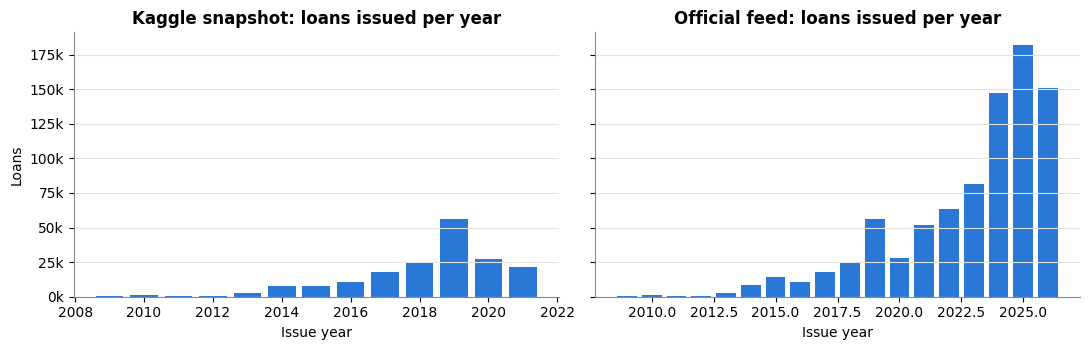

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, dates) in zip(axes, [("Kaggle snapshot", kaggle["LoanDate"]),
                                    ("Official feed", official["loan_issued_at"])]):
    per_year = dates.dt.year.value_counts().sort_index()
    ax.bar(per_year.index, per_year.values, color=BLUE, width=0.8)
    ax.set_title(f"{name}: loans issued per year")
    ax.set_xlabel("Issue year")
axes[0].set_ylabel("Loans")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v / 1000:,.0f}k")
plt.tight_layout()
plt.show()

## 6. Countries

In [14]:
countries = pd.concat({
    "kaggle": kaggle["Country"].value_counts(),
    "official": official["country"].value_counts(),
}, axis=1).fillna(0).astype(int).sort_values("official", ascending=False)
countries["official_pct"] = (countries["official"] / countries["official"].sum() * 100).round(2)
countries

,kaggle,official,official_pct
Finland,0,461131,54.65
Estonia,0,248693,29.47
Netherlands,0,73994,8.77
Spain,0,34221,4.06
Latvia,0,13633,1.62
Denmark,0,11699,1.39
Slovakia,0,346,0.04
Lithuania,0,38,0.00
SK,296,0,0.00
ES,26270,0,0.00


The two sources code countries differently: Kaggle uses ISO codes (`EE`, `FI`, `ES`, `SK`), the official feed uses full names. Kaggle covers exactly the four countries in the README scope; the official feed adds the Netherlands, Latvia, Denmark and Lithuania, which have no borrower features. Slovakia is very small in both, so it will need a scope decision in `docs/decision_log.md`.

## 7. The joined population

Join on the GUID (compared in upper case): borrower features from Kaggle, outcomes from the official feed.

In [15]:
joined = kaggle.assign(_key=k_id.str.upper()).merge(
    official.assign(_key=o_id.str.upper()), on="_key", how="inner", validate="one_to_one"
)
summary = pd.Series({
    "Kaggle loans": len(kaggle),
    "Official loans": len(official),
    "Joined (features + outcomes)": len(joined),
    "Official only (outcomes, no features)": len(official) - len(joined),
})
summary.map("{:,}".format)

Kaggle loans                             179,235
Official loans                           843,755
Joined (features + outcomes)             179,235
Official only (outcomes, no features)    664,520
dtype: object

In [16]:
# Sanity check: matched rows should agree on fields both sources describe.
ISO_TO_NAME = {"EE": "Estonia", "FI": "Finland", "ES": "Spain", "SK": "Slovakia"}
country_mismatch = joined["Country"].map(ISO_TO_NAME) != joined["country"]
amount_gap = (joined["Amount"] - joined["issued_amount"]).abs()
print(f"Joined loans that disagree on country: {country_mismatch.sum():,} of {len(joined):,}")
print(f"Joined loans whose amount differs by more than 1 EUR: {(amount_gap > 1).sum():,}")
joined.loc[country_mismatch, ["LoanId", "Country", "country", "LoanDate", "loan_issued_at",
                              "Amount", "issued_amount", "Status", "loan_status"]]

Joined loans that disagree on country: 1 of 179,235
Joined loans whose amount differs by more than 1 EUR: 1


,LoanId,Country,country,LoanDate,loan_issued_at,Amount,issued_amount,Status,loan_status
50252,F9E26B81-AEE4-442B-B4FC-A87400B4F8E1,EE,Finland,2018-01-26,2018-01-26 11:24:38,8449.0,8449.0,Late,Defaulted


One joined loan has the same ID, issue date and amount in both sources but a different country (Kaggle: Estonia, official: Finland), most likely a record corrected after the 2021 snapshot. The warehouse keeps it and flags it in `loans.country_mismatch`; the Kaggle (application-time) country is used. See decision D-007.

## 8. A candidate default target

The official feed carries `has_default_within_12_months` and `is_default`. A 12-month default flag matches the project's 12-month PD horizon, so it is the first candidate target. It is only mature for loans issued at least 12 months before the feed date.

In [17]:
for col in ["has_default_within_12_months", "is_default"]:
    print(col)
    print(official[col].value_counts(dropna=False).rename("loans").to_string(), "\n")

has_default_within_12_months
has_default_within_12_months
0.0    564983
NaN    188117
1.0     90655 

is_default
is_default
0.0    719332
1.0    116710
NaN      7713 



In [18]:
feed_date = official["loan_issued_at"].max()
mature = official["loan_issued_at"] <= feed_date - pd.DateOffset(months=12)
print(f"Feed date: {feed_date:%Y-%m-%d}. Mature loans (issued 12+ months before): {mature.sum():,}")
print("Target missing among mature loans:",
      f"{official.loc[mature, 'has_default_within_12_months'].isna().sum():,}")
print("Target missing among immature loans:",
      f"{official.loc[~mature, 'has_default_within_12_months'].isna().sum():,} of {(~mature).sum():,}")

dr = (official[mature]
      .groupby(official.loc[mature, "loan_issued_at"].dt.year)["has_default_within_12_months"]
      .agg(loans="size", target_known="count", default_rate="mean"))
dr["default_rate_pct"] = (dr["default_rate"] * 100).round(1)
dr[["loans", "target_known", "default_rate_pct"]]

Feed date: 2026-09-30. Mature loans (issued 12+ months before): 644,037
Target missing among mature loans: 0
Target missing among immature loans: 188,117 of 199,718


,loans,target_known,default_rate_pct
loan_issued_at,,,
2009,667,667,33.7
2010,1163,1163,26.7
2011,451,451,15.1
2012,457,457,9.2
2013,2519,2519,13.3
2014,8713,8713,24.9
2015,14338,14338,18.3
2016,10539,10539,34.8
2017,17990,17990,36.5


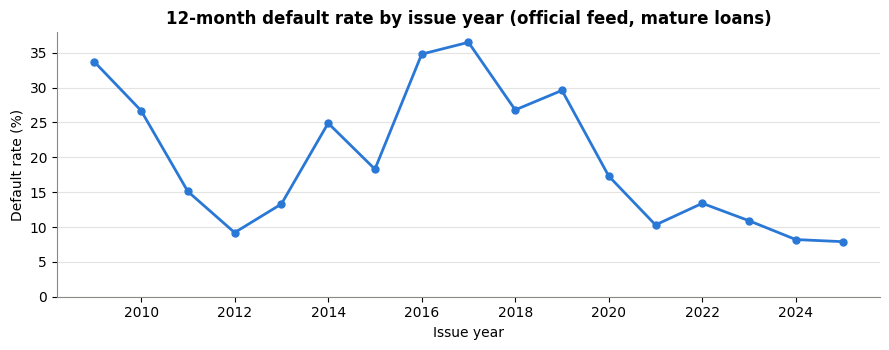

In [19]:
fig, ax = plt.subplots()
ax.plot(dr.index, dr["default_rate_pct"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set_title("12-month default rate by issue year (official feed, mature loans)")
ax.set_xlabel("Issue year")
ax.set_ylabel("Default rate (%)")
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

In [20]:
# Same rate on the joined population, which is what the scorecard can be trained on.
jm = joined["loan_issued_at"] <= feed_date - pd.DateOffset(months=12)
print(f"Joined loans that are mature: {jm.sum():,}")
print(f"12-month default rate (joined, mature): {joined.loc[jm, 'has_default_within_12_months'].mean():.2%}")

Joined loans that are mature: 179,235
12-month default rate (joined, mature): 25.91%


## 9. Findings and what they mean for the warehouse

Read the numbers above; the conclusions below follow from them.

1. **Data integrity.** Both raw files match their manifest hashes, so this analysis is tied to a recorded snapshot.
2. **Two complementary sources.** Kaggle has the borrower detail (demographics, income, liabilities, credit scores) up to mid-2021. The official feed has fewer columns, mostly outcomes, but covers many more loans and runs to the present.
3. **No shared column names.** The warehouse must rename columns explicitly, with a clear source prefix.
4. **Join key.** `LoanId = loan_id` matches every Kaggle loan (compared in upper case for safety). `LoanNumber` is not a join key. Country is coded differently (ISO codes vs names) and needs a mapping.
5. **Modelling population.** Only the joined loans have both features and outcomes, so they are the training population for the scorecard. Official-only loans are still useful for portfolio default rates and the ECL step.
6. **Target.** `has_default_within_12_months` fits the 12-month PD horizon. Only loans issued 12+ months before the feed date are mature and usable.
7. **Scope.** The joined population covers exactly the README countries (Estonia, Finland, Spain, Slovakia). Slovakia is too small to model on its own and needs a documented decision.
8. **Default rate moves a lot over time.** The 12-month default rate swings strongly by issue year, which matters for the out-of-time split and for linking defaults to macro scenarios.

**Next notebook / step:** build `pdengine.warehouse` (Parquet + DuckDB, GUID join, source-prefixed columns, country mapping), then a full data audit in `02_data_audit.ipynb`.